# Phase 4 - Recorded places and unusual weeks in Gaza
**DS312, Group 7 | Historical ACLED snapshot | November 24, 2026**

## S1. Purpose and reading guide
We group nearby recorded places with **DBSCAN** and screen completed district-weeks against earlier local activity. These complementary families support documentary review: where to look and which weeks deserve context. Neither estimates unrecorded harm, intent or legal responsibility.

Read S2 for inputs and validation, S3-S4 for geography, S5-S6 for unusual weeks, and S7 for findings and recommendations. Figure and table names are readable citations; use the notebook Outline to navigate. Phase 1-3 notebooks and source data are preserved. This separate report does not integrate all phases.

The rubric requires two families, a simple baseline, at least two settings per family, appropriate evaluation, interpretation, limitations and 3-5 recommendations. S4 compares geography with district totals; S5 supplies the simple temporal baseline. Without verified review labels, accuracy, F1 and causal claims would be inappropriate.

## S2. Inputs, timing and frozen design
Phase 2 created the four CSVs; Phase 3 loaded them without changing their populations. We verify those definitions again below. Files overlap and must not be added together.

| Input | Row and scope | Key | Useful information |
|---|---|---|---|
| events_clean | One Gaza-coded event, 2022-01-01 to 2025-09-30; includes coast | event ID | Cohort, district, political denominator, source/notes |
| gaza_week | One post-cutoff Gaza calendar week, including zeros/coast | area, Saturday | Context and reconciliation |
| district_week | One known district/calendar week, including zeros/coast | district, Saturday | Counts, shares and eligible history |
| focal_incidents | One post-cutoff land focal event | event ID | Coordinates, precision and traceability |

Focal means targeting flagged **and** the exact `Civilians (Palestine)` actor label in either actor field. Land excludes location labels starting `Coast of`; it is a coding rule, not a coastline test. Political violence is the recorded disorder label. Missing districts stay in Gaza totals.

| Feature | Available | Use / missing rule |
|---|---|---|
| Latitude/longitude in radians | Snapshot | Spatial distance only; Earth radius 6371.0088 km |
| Current focal/political count and share | After week closes | Screen current week; share undefined if political count is zero |
| Previous-week count / previous-four-week sum | Before current week | Require every preceding calendar week eligible; never bridge gaps |
| District | Snapshot | Separate temporal models, descriptive profiles |
| ID, source and notes | Snapshot | Traceability only; never distance or predictor inputs |

**Frozen before fitting:** spatial radii 0.5/0.75/1/1.25/1.5/2/3 km, min_samples 10/50, full and precision-1 populations. Retain 1 km/50 as a descriptive reference at the center of the neighboring 0.75-1.25 km check, not as an optimum; reject a single robust partition claim if it is unstable. Silhouette is a diagnostic, not a selection target. Compare precision and two equal-duration spatial time blocks separately.

Temporal windows are 8/12/16 earlier calendar weeks, |modified z| > 3.5, count MAD floor 1; shares use no count floor and flat shares are unscored. Keep 12 weeks as the prespecified middle-window reference, and report all windows on common coverage. Thresholds and windows will not be tuned against assessment outcomes.

Chronological blocks: first 52 completed weeks establish history, next 26 weeks provide internal tuning, remaining completed weeks provide retrospective assessment. Rolling baselines use only preceding eligible observations, including earlier assessment weeks as time advances. Optional Isolation Forest uses fixed district-specific fits on the first block, two small feature subsets and max_samples 32/auto; at least 40 complete eligible training rows required. Cutoffs use the 90th percentile of earlier tuning anomaly scores (a review budget, not an anomaly prevalence estimate). Choose the smallest feature subset and then the max_samples setting closest to the 10% tuning burden; ties favor 32. Freeze before assessment. No imputation/scaling is needed for these finite count features and tree models. This fixed-origin detector is an earlier-only comparison to rolling baselines.

**All these historical dates were already explored in Phase 3.** Later blocks are internal retrospective checks, not untouched final tests. New data and independent review are required for unseen evaluation. Alerts are issued after a completed week, not forecasts.

In [1]:
import os, sys, json, hashlib, platform
from pathlib import Path
os.environ.setdefault('OMP_NUM_THREADS','1')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import sklearn
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, adjusted_rand_score
from IPython.display import display, Markdown
%matplotlib inline
ROOT=Path.cwd()
assert (ROOT/'data/processed').is_dir(), 'Run from project root'
OUT=ROOT/'task4 tasks/implementation'
SEED=42; EARTH_KM=6371.0088
plt.rcParams.update({'figure.dpi':115,'axes.titlesize':11,'axes.labelsize':10,'font.size':10})
pd.set_option('display.max_columns',20)
pd.set_option('display.max_colwidth',90)
def report(text): display(Markdown(text))
def table(df,name):
    print(name); display(df)
    df.to_csv(OUT/(name.split(':')[0].replace(' ','_')+'.csv'),index=False)
def figure(fig,name):
    fig.tight_layout();fig.savefig(OUT/(name+'.png'),dpi=140,bbox_inches='tight');plt.show()
protected=json.loads((OUT/'protected_hashes.json').read_text())
def verify_protected():
    assert all(hashlib.sha256((ROOT/Path(p)).read_bytes()).hexdigest()==v for p,v in protected.items()), 'Protected file changed'
verify_protected()
print('Runtime:',sys.version.split()[0], '| pandas',pd.__version__,'| numpy',np.__version__,'| sklearn',sklearn.__version__)
(OUT/'runtime.json').write_text(json.dumps({'python':sys.version,'executable':sys.executable,'pandas':pd.__version__,'numpy':np.__version__,'sklearn':sklearn.__version__,'seed':SEED},indent=2))
def load(name,dates):
    df=pd.read_csv(ROOT/'data/processed'/name,parse_dates=dates)
    for c in df.columns:
        if c in ['complete_week','history_eligible','political_activity_recorded','targeting_flagged','political_violence','focal_event','geo_precision_1','time_precision_1','coastal_location','land_spatial_eligible','district_missing','high_fatalities_review']:
            vals=df[c].astype(str);assert vals.isin(['True','False']).all();df[c]=vals.map({'True':True,'False':False}).astype(bool)
    for c in ['geo_precision','time_precision']:
        if c in df:
            assert df[c].isin([1,2,3]).all();df[c]=pd.Categorical(df[c],categories=[1,2,3],ordered=True)
    return df
master=load('acled_events_clean.csv',['event_date','month_start','week_start'])
gw=load('acled_gaza_week.csv',['week_start','week_end'])
dw=load('acled_district_week.csv',['week_start','week_end'])
inc=load('acled_focal_incidents.csv',['event_date','month_start','week_start'])
assert [x.shape for x in [master,gw,dw,inc]]==[(26664,43),(104,13),(520,14),(10583,45)]
assert master.admin1.eq('Gaza Strip').all() and master.event_id_cnty.is_unique
assert master.targeting_flagged.equals(master.civilian_targeting.eq('Civilian targeting'))
focal=master.targeting_flagged & (master.actor1.eq('Civilians (Palestine)')|master.actor2.eq('Civilians (Palestine)'))
assert master.focal_event.equals(focal)
assert master.political_violence.equals(master.disorder_type.str.split(';').apply(lambda a:'Political violence' in [s.strip() for s in a]))
assert master.loc[focal,'political_violence'].all()
assert master.coastal_location.equals(master.location.str.startswith('Coast of'))
post=master.event_date.ge('2023-10-07')
assert master.land_spatial_eligible.equals(post & focal & ~master.coastal_location)
assert inc.event_id_cnty.tolist()==master.loc[master.land_spatial_eligible,'event_id_cnty'].tolist()
assert np.allclose(inc[['latitude_rad','longitude_rad']],np.radians(inc[['latitude','longitude']]))
assert inc.latitude.between(-90,90).all() and inc.longitude.between(-180,180).all()
assert inc.geo_precision_1.equals(inc.geo_precision.eq(1))
for w,area in [(gw,'admin1'),(dw,'admin2')]:
    assert not w.duplicated([area,'week_start']).any()
    assert w.week_end.equals(w.week_start+pd.Timedelta(days=6))
    assert w.complete_week.equals(w.week_end.le('2025-09-30'))
    assert w.history_eligible.equals(w.complete_week & w.political_events.gt(0))
    assert np.allclose(w.focal_share,w.focal_events/w.political_events.where(w.political_events.gt(0)),equal_nan=True)
    assert w.focal_events.le(w.political_events).all()
    for _,g in w.groupby(area):
        g=g.sort_values('week_start');h=g.focal_events.where(g.history_eligible)
        assert g.week_start.diff().dropna().eq(pd.Timedelta(days=7)).all()
        for c,expected in [('focal_count_for_history',h),('previous_week_focal',h.shift(1)),('previous_four_weeks_focal',h.shift(1).rolling(4).sum())]:
            assert np.allclose(g[c],expected,equal_nan=True)
    source=master.loc[post & master[area].notna()]
    expected=source.groupby([area,'week_start']).agg(recorded_events=('event_id_cnty','size'),political_events=('political_violence','sum'),focal_events=('focal_event','sum'))
    actual=w.set_index([area,'week_start'])[expected.columns]
    assert actual.equals(expected.reindex(actual.index,fill_value=0).astype(actual.dtypes))
weeks=sorted(gw.loc[gw.complete_week,'week_start'])
TRAIN_END=weeks[51]; TUNE_END=weeks[77]; ASSESS_START=weeks[78]
def block(date): return 'history' if date<=TRAIN_END else ('tuning' if date<=TUNE_END else 'assessment')
dw['block']=dw.week_start.map(block)
blocks=pd.DataFrame([{'block':n,'start':min(v),'last_week_start':max(v),'weeks':len(v)} for n in ['history','tuning','assessment'] if (v:=[d for d in weeks if block(d)==n])])
table(blocks,'Table 1: Chronological blocks')
table(dw.loc[~dw.complete_week,['admin2','week_start','week_end','focal_events','political_events']],'Table 2: Excluded partial weeks')
pops=pd.DataFrame({'population':['Gaza master','Gaza weeks','District weeks','Land focal','Precision-1 land focal'],'rows':[len(master),len(gw),len(dw),len(inc),int(inc.geo_precision_1.sum())]})
table(pops,'Table 3: Population accounting')
print('Missing district focal post-cutoff:',int(master.loc[post & master.admin2.isna(),'focal_event'].sum()))
print('All input, reconciliation, eligibility and lag assertions passed.')

Runtime: 3.12.14 | pandas 3.1.1 | numpy 2.5.5 | sklearn 1.9.1


Table 1: Chronological blocks


,block,start,last_week_start,weeks
0,history,2023-10-07,2024-09-28,52
1,tuning,2024-10-05,2025-03-29,26
2,assessment,2025-04-05,2025-09-20,25


Table 2: Excluded partial weeks


,admin2,week_start,week_end,focal_events,political_events
103,Deir El Balah,2025-09-27,2025-10-03,21,26
207,Gaza City,2025-09-27,2025-10-03,40,78
311,Khan Yunis,2025-09-27,2025-10-03,14,22
415,North Gaza,2025-09-27,2025-10-03,0,0
519,Rafah,2025-09-27,2025-10-03,5,7


Table 3: Population accounting


,population,rows
0,Gaza master,26664
1,Gaza weeks,104
2,District weeks,520
3,Land focal,10583
4,Precision-1 land focal,7576


Missing district focal post-cutoff: 3
All input, reconciliation, eligibility and lag assertions passed.


**Input interpretation (Tables 1-3).** The last week starts September 27, 2025 and is incomplete; all five district rows are excluded from scoring. Zero counts remain in the calendar, but a zero political denominator makes a share undefined and its count ineligible as local history. The three post-cutoff focal events without districts remain in Gaza totals. Table 1 fixes the chronological dates before modeling.

## S3. Which nearby recorded places form groups?
Following Menorias Module 7 Sections 7.4-7.4.4, DBSCAN connects dense neighborhoods without choosing a fixed group count. **eps** is the neighborhood radius; **min_samples** counts records including the point itself. A border record touches a dense group; **noise** means unassigned by this setting, not verified error or harm.

We use haversine distance on radians and set `eps = radius_km / 6371.0088`. Geographic axes are not standardized. Because many records share coordinates, fitting unique coordinate pairs with their record counts as weights preserves event density and avoids a large duplicate distance graph. Unique pairs retain first-occurrence order; the fit and event assignments are deterministic. IDs and notes do not enter distance calculations.

Figure 1 measures distance to neighbor 10/50 **including self**, consistent with DBSCAN. Repetition can make these distances zero. A curve without a clear knee does not establish an optimum; the frozen grid checks nearby radii and wider merging behavior.

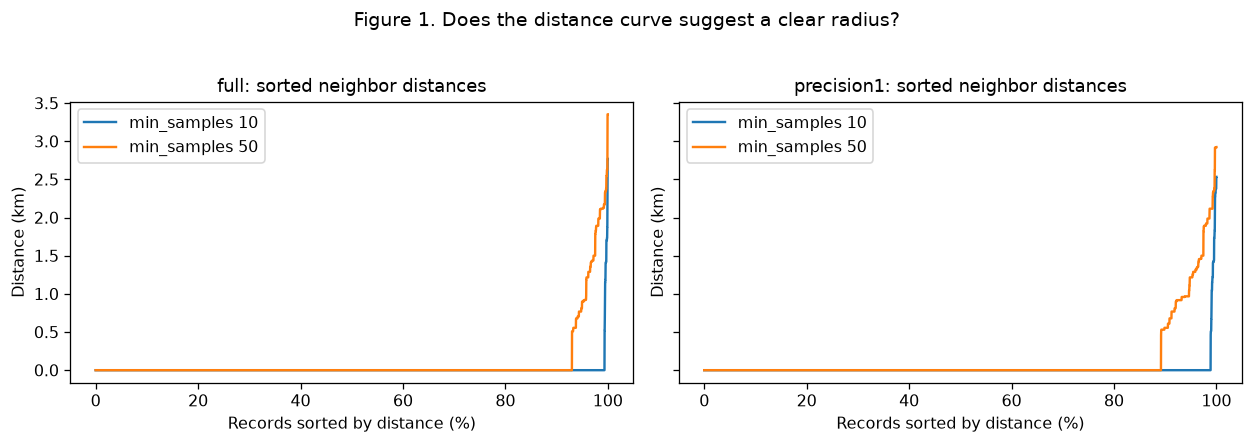

Table 4: Neighbor distance diagnostics


,population,min_samples,zero_distance_pct,p95_km,max_km
0,full,10,99.348011,0.000000,2.769620
1,full,50,92.988756,0.899247,3.353791
2,precision1,10,98.864836,0.000000,2.533836
3,precision1,50,89.176346,1.216400,2.924665


Table 5: Spatial candidate accounting


,population,radius_km,min_samples,records,coordinate_pairs,clusters,noise_records,noise_pct,smallest_cluster,median_cluster,largest_cluster
0,full,0.50,10,10583,101,81,67,0.633091,10,88.0,491
1,full,0.75,10,10583,101,74,62,0.585845,10,103.5,491
2,full,1.00,10,10583,101,58,58,0.548049,10,114.5,852
3,full,1.25,10,10583,101,42,49,0.463007,10,113.5,1295
4,full,1.50,10,10583,101,30,28,0.264575,10,134.0,2333
5,full,2.00,10,10583,101,19,10,0.094491,10,130.0,4484
6,full,3.00,10,10583,101,1,0,0.000000,10583,10583.0,10583
7,full,0.50,50,10583,101,55,740,6.992346,51,172.0,491
8,full,0.75,50,10583,101,54,583,5.508835,51,163.0,491
9,full,1.00,50,10583,101,43,447,4.223755,51,197.0,852


28 candidate fits; weighted/event-level reference partitions agree exactly in both populations.


**Figure 1 interpretation.** Zero-distance neighbors dominate where many events share a recorded place (Table 4); these are repeated records at coordinates, not duplicate event IDs. Table 5 shows how the group count and noise change across the frozen radii. Neither a high-density coordinate nor a curve bend validates an exact incident site.

In [2]:
RADII=[0.5,0.75,1.,1.25,1.5,2.,3.]; MIN_SAMPLES=[10,50]
populations={'full':inc.copy(),'precision1':inc.loc[inc.geo_precision_1].copy()}
assignments={}; spatial_rows=[]; kd_rows=[]
fig,axes=plt.subplots(1,2,figsize=(11,3.7),sharey=True)
for ax,(pop,d) in zip(axes,populations.items()):
    X=d[['latitude_rad','longitude_rad']].to_numpy()
    nn=NearestNeighbors(n_neighbors=50,metric='haversine',algorithm='ball_tree').fit(X)
    dist,_=nn.kneighbors(X)
    for m in MIN_SAMPLES:
        kdist=np.sort(dist[:,m-1]*EARTH_KM)
        ax.plot(np.linspace(0,100,len(kdist)),kdist,label=f'min_samples {m}')
        kd_rows.append({'population':pop,'min_samples':m,'zero_distance_pct':100*np.isclose(kdist,0,atol=1e-10).mean(),'p95_km':np.quantile(kdist,.95),'max_km':kdist.max()})
    ax.set(title=f'{pop}: sorted neighbor distances',xlabel='Records sorted by distance (%)',ylabel='Distance (km)');ax.legend()
fig.suptitle('Figure 1. Does the distance curve suggest a clear radius?',y=1.03)
figure(fig,'Figure_1_kdistance')
table(pd.DataFrame(kd_rows),'Table 4: Neighbor distance diagnostics')
def geo_fit(d,r,m):
    pairs=pd.MultiIndex.from_frame(d[['latitude_rad','longitude_rad']])
    inverse,unique=pd.factorize(pairs,sort=False)
    X=np.array(unique.tolist(),dtype=float); weights=np.bincount(inverse)
    lab=DBSCAN(eps=r/EARTH_KM,min_samples=m,metric='haversine',algorithm='ball_tree',n_jobs=1).fit_predict(X,sample_weight=weights)
    return lab[inverse]
for pop,d in populations.items():
    for m in MIN_SAMPLES:
        for r in RADII:
            labels=geo_fit(d,r,m)
            assignments[(pop,r,m)]=pd.Series(labels,index=d.event_id_cnty,name='cluster')
            sizes=pd.Series(labels[labels>=0]).value_counts()
            spatial_rows.append({'population':pop,'radius_km':r,'min_samples':m,'records':len(d),'coordinate_pairs':len(d[['latitude','longitude']].drop_duplicates()),'clusters':len(sizes),'noise_records':int((labels<0).sum()),'noise_pct':100*(labels<0).mean(),'smallest_cluster':int(sizes.min()) if len(sizes) else 0,'median_cluster':float(sizes.median()) if len(sizes) else 0,'largest_cluster':int(sizes.max()) if len(sizes) else 0})
            assert sizes.sum()+(labels<0).sum()==len(d)
spatial=pd.DataFrame(spatial_rows)
table(spatial,'Table 5: Spatial candidate accounting')
long_assign=pd.concat([s.rename('cluster').reset_index().assign(population=k[0],radius_km=k[1],min_samples=k[2]) for k,s in assignments.items()],ignore_index=True)
long_assign.to_csv(OUT/'spatial_assignments.csv',index=False)
assert len(long_assign)==sum(len(d)*len(RADII)*len(MIN_SAMPLES) for d in populations.values())
# Check weighted compression against the literal event fit at the reference setting.
from sklearn.metrics.cluster import contingency_matrix
for pop,d in populations.items():
    literal=DBSCAN(eps=1/EARTH_KM,min_samples=50,metric='haversine',algorithm='ball_tree',n_jobs=1).fit_predict(d[['latitude_rad','longitude_rad']])
    compressed=assignments[(pop,1.,50)].to_numpy()
    assert np.array_equal(literal<0,compressed<0)
    assert adjusted_rand_score(literal,compressed)==1.
print('28 candidate fits; weighted/event-level reference partitions agree exactly in both populations.')
report('**Figure 1 interpretation.** Zero-distance neighbors dominate where many events share a recorded place (Table 4); these are repeated records at coordinates, not duplicate event IDs. Table 5 shows how the group count and noise change across the frozen radii. Neither a high-density coordinate nor a curve bend validates an exact incident site.')

## S4. Does clustering add detail beyond district totals?
We compare neighboring settings by **co-membership Jaccard**: among event pairs grouped together by either setting, what fraction are grouped together by both? It ignores label numbers and does not count pairs of noise records as a group. Noise-status agreement is shown separately. This measures sensitivity, not accuracy against true labels.

Silhouette compares within-group and between-group distances; it is calculated only on non-noise records with at least two groups. To limit cost, use a uniform sample of up to 1,500 event records without replacement (seed 42), reporting represented groups. A group lost in sampling is not silently presented as fully evaluated. Dense repeated coordinates can produce high silhouettes even when radius sensitivity is substantial (Menorias Sections 7.5-7.6).

Table 6: Spatial evaluation with noise


,population,radius_km,min_samples,records,coordinate_pairs,clusters,noise_records,noise_pct,smallest_cluster,median_cluster,largest_cluster,silhouette,silhouette_n,groups_represented,silhouette_scope
0,full,0.50,10,10583,101,81,67,0.6331,10,88.0,491,0.9980,1500,78,sampled
1,full,0.75,10,10583,101,74,62,0.5858,10,103.5,491,0.9690,1500,71,sampled
2,full,1.00,10,10583,101,58,58,0.5480,10,114.5,852,0.8121,1500,57,sampled
3,full,1.25,10,10583,101,42,49,0.4630,10,113.5,1295,0.6421,1500,39,sampled
4,full,1.50,10,10583,101,30,28,0.2646,10,134.0,2333,0.5254,1500,30,sampled
5,full,2.00,10,10583,101,19,10,0.0945,10,130.0,4484,0.2823,1500,18,sampled
6,full,3.00,10,10583,101,1,0,0.0000,10583,10583.0,10583,NaN,1500,1,unavailable: fewer than two represented groups
7,full,0.50,50,10583,101,55,740,6.9923,51,172.0,491,1.0000,1500,55,sampled
8,full,0.75,50,10583,101,54,583,5.5088,51,163.0,491,0.9801,1500,54,sampled
9,full,1.00,50,10583,101,43,447,4.2238,51,197.0,852,0.8248,1500,43,sampled


Table 7: Membership sensitivity


,comparison,setting_a,setting_b,common_events,pair_jaccard,noise_status_agreement
0,neighbor radii,"('full', 0.5, 10)","('full', 0.75, 10)",10583,0.9478,0.9995
1,neighbor radii,"('full', 0.75, 10)","('full', 1.0, 10)",10583,0.6789,0.9996
2,neighbor radii,"('full', 1.0, 10)","('full', 1.25, 10)",10583,0.5557,0.9991
3,neighbor radii,"('full', 1.25, 10)","('full', 1.5, 10)",10583,0.5682,0.9980
4,neighbor radii,"('full', 1.5, 10)","('full', 2.0, 10)",10583,0.4355,0.9983
5,neighbor radii,"('full', 2.0, 10)","('full', 3.0, 10)",10583,0.2463,0.9991
6,neighbor radii,"('full', 0.5, 50)","('full', 0.75, 50)",10583,0.9460,0.9852
7,neighbor radii,"('full', 0.75, 50)","('full', 1.0, 50)",10583,0.6768,0.9871
8,neighbor radii,"('full', 1.0, 50)","('full', 1.25, 50)",10583,0.5548,0.9912
9,neighbor radii,"('full', 1.25, 50)","('full', 1.5, 50)",10583,0.5677,0.9941


Table 8: District count baseline


,admin2,records,places,share_pct
1,Gaza City,3436,25,32.47
2,Khan Yunis,2275,28,21.50
0,Deir El Balah,2264,14,21.39
3,North Gaza,1321,18,12.48
4,Rafah,1287,16,12.16


Table 9: Largest reference group profiles


C:\Users\USER\AppData\Local\Temp\ipykernel_6196\957370669.py:45: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  table(profiles.groupby('population',sort=False).head(6).round(2),'Table 9: Largest reference group profiles')


,population,cluster,records,districts,main_place,start,end,coordinate_pairs,repeated_coordinate_pct,precision1_pct
1,full,1,852,Gaza City,Gaza - Shujaiyya,2023-10-07,2025-09-30,4,99.53,79.34
0,full,0,771,Khan Yunis,Khan Yunis - West (Municipal Stadium),2023-10-07,2025-09-30,7,99.09,66.54
9,full,9,537,Rafah,Rafah,2023-10-07,2025-09-27,7,98.70,64.80
7,full,7,491,Gaza City,Gaza - Az Zaytun,2023-10-07,2025-09-30,1,99.80,83.30
11,full,11,440,Deir El Balah,An Nusayrat - Unspecified,2023-10-08,2025-09-30,1,99.77,89.55
8,full,8,435,North Gaza,Jabalya,2023-10-07,2025-09-12,1,99.77,82.07
44,precision1,1,676,Gaza City,Gaza - Shujaiyya,2023-10-07,2025-09-30,4,99.41,100.00
43,precision1,0,513,Khan Yunis,Khan Yunis - Unspecified,2023-10-07,2025-09-30,7,98.64,100.00
48,precision1,5,409,Gaza City,Gaza - Az Zaytun,2023-10-07,2025-09-30,1,99.76,100.00
52,precision1,9,394,Deir El Balah,An Nusayrat - Unspecified,2023-10-08,2025-09-30,1,99.75,100.00


Table 10: Documentary entry records


,population,cluster,event_id_cnty,event_date,admin2,location,event_type,source,records,notes_excerpt
1,full,1,PSE37614,2023-10-07,Gaza City,Gaza - Shujaiyya,Explosions/Remote violence,Palestine News and Information Agency,852,"On 7 October 2023, at approximately 14:47, Israeli warplanes conducted a number of rai..."
0,full,0,PSE37596,2023-10-07,Khan Yunis,Khan Yunis - West (Municipal Stadium),Explosions/Remote violence,Haaretz,771,"On 7 October 2023, Israeli warplanes conducted an airstrike in Khan Yunis (Khan Yunis ..."
44,precision1,1,PSE37614,2023-10-07,Gaza City,Gaza - Shujaiyya,Explosions/Remote violence,Palestine News and Information Agency,676,"On 7 October 2023, at approximately 14:47, Israeli warplanes conducted a number of rai..."
9,full,9,PSE37626,2023-10-07,Rafah,Rafah,Explosions/Remote violence,Palestine News and Information Agency,537,"On 7 October 2023, Israeli warplanes conducted an airstrike on a residential building ..."


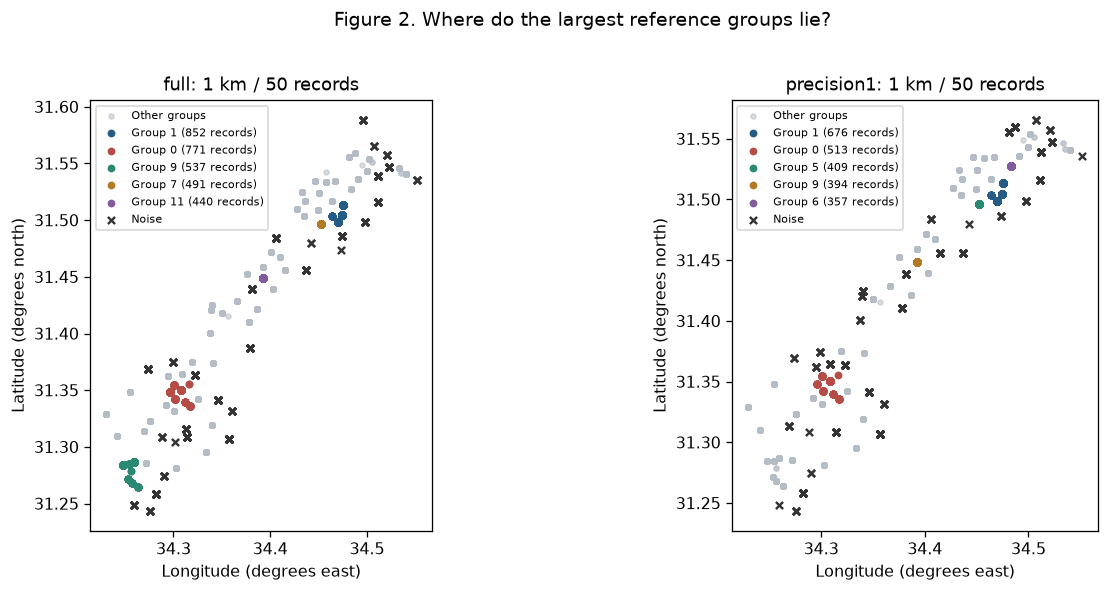

Table 11: Spatial time restriction


,period,start,end,records,clusters,noise_pct
0,earlier,2023-10-07,2024-10-04,5502,33,9.541985
1,later,2024-10-05,2025-09-30,5081,34,11.237945


Shared coordinate places: 84 | place-pair Jaccard: 0.773


**Figure 2 and Tables 6-11 interpretation.** At the prespecified 1 km/50 reference, 43 groups contain recorded land places; 4.2% of records are noise. At 3 km/50, 1 group remains, so radius materially changes the picture. The largest district is Gaza City (32.5% of land focal records); profiles split district totals into named-place groups, but repeated coordinates drive much of that detail. The two equal-duration spatial blocks share 84 coordinate places, with place-pair Jaccard 0.77; this is not event-level validation. No single robust or optimal partition is established. Use the reference groups only as traceable review bins, alongside district totals and the precision comparison. Full source excerpts are in cluster_source_examples.csv; no documentary outcomes have been verified.

In [3]:
def pair_jaccard(a,b):
    a=np.asarray(a);b=np.asarray(b)
    choose=lambda x:np.sum(np.asarray(x,dtype=float)*(np.asarray(x,dtype=float)-1)/2)
    pa=choose(pd.Series(a[a>=0]).value_counts());pb=choose(pd.Series(b[b>=0]).value_counts())
    mask=(a>=0)&(b>=0)
    inter=choose(pd.DataFrame({'a':a[mask],'b':b[mask]}).value_counts())
    return inter/(pa+pb-inter) if pa+pb-inter else np.nan
silrows=[]
for row in spatial.to_dict('records'):
    key=(row['population'],row['radius_km'],row['min_samples']);d=populations[key[0]]
    labels=assignments[key].to_numpy();idx=np.flatnonzero(labels>=0)
    chosen=np.random.default_rng(SEED).choice(idx,size=min(1500,len(idx)),replace=False)
    represented=len(np.unique(labels[chosen]));score=np.nan
    reason='one non-noise group' if row['clusters']<2 else 'sampled' if len(chosen)<len(idx) else 'all non-noise'
    if 2<=represented<len(chosen): score=silhouette_score(d[['latitude_rad','longitude_rad']].to_numpy()[chosen],labels[chosen],metric='haversine')
    else: reason='unavailable: fewer than two represented groups'
    silrows.append({**row,'silhouette':score,'silhouette_n':len(chosen),'groups_represented':represented,'silhouette_scope':reason})
spatial_eval=pd.DataFrame(silrows)
table(spatial_eval.round(4),'Table 6: Spatial evaluation with noise')
stability=[]
def compare(k1,k2,kind):
    a=assignments[k1];b=assignments[k2];ids=a.index.intersection(b.index);a=a.loc[ids].to_numpy();b=b.loc[ids].to_numpy()
    stability.append({'comparison':kind,'setting_a':str(k1),'setting_b':str(k2),'common_events':len(ids),'pair_jaccard':pair_jaccard(a,b),'noise_status_agreement':np.mean((a<0)==(b<0))})
for pop in populations:
    for m in MIN_SAMPLES:
        for a,b in zip(RADII[:-1],RADII[1:]):compare((pop,a,m),(pop,b,m),'neighbor radii')
    for r in RADII:compare((pop,r,10),(pop,r,50),'density')
for r in RADII:
    for m in MIN_SAMPLES:compare(('full',r,m),('precision1',r,m),'precision restriction')
stability=pd.DataFrame(stability)
table(stability.round(4),'Table 7: Membership sensitivity')
district_baseline=inc.groupby('admin2').agg(records=('event_id_cnty','size'),places=('location','nunique')).reset_index().sort_values('records',ascending=False)
district_baseline['share_pct']=100*district_baseline.records/len(inc)
table(district_baseline.round(2),'Table 8: District count baseline')
profiles=[]; examples=[]
for pop,d in populations.items():
    d=d.copy();d['cluster']=assignments[(pop,1.,50)].to_numpy()
    for label,g in d.loc[d.cluster>=0].groupby('cluster'):
        profiles.append({'population':pop,'cluster':label,'records':len(g),'districts':'; '.join(g.admin2.unique()),'main_place':g.location.mode().iloc[0],'start':g.event_date.min(),'end':g.event_date.max(),'coordinate_pairs':len(g[['latitude','longitude']].drop_duplicates()),'repeated_coordinate_pct':100*g.duplicated(['latitude','longitude']).mean(),'precision1_pct':100*g.geo_precision_1.mean()})
        # Earliest event provides a reproducible documentary entry, not an outcome judgment.
        e=g.sort_values(['event_date','event_id_cnty']).iloc[0]
        examples.append({'population':pop,'cluster':label,**e[['event_id_cnty','event_date','admin2','location','event_type','source','notes']].to_dict()})
profiles=pd.DataFrame(profiles).sort_values(['population','records'],ascending=[True,False]);examples=pd.DataFrame(examples)
profiles.to_csv(OUT/'all_cluster_profiles.csv',index=False);examples.to_csv(OUT/'cluster_source_examples.csv',index=False)
table(profiles.groupby('population',sort=False).head(6).round(2),'Table 9: Largest reference group profiles')
show_examples=examples.merge(profiles[['population','cluster','records']],on=['population','cluster']).sort_values('records',ascending=False).head(4).copy()
show_examples['notes_excerpt']=show_examples.notes.str.slice(0,180)
table(show_examples.drop(columns='notes'),'Table 10: Documentary entry records')
fig,axes=plt.subplots(1,2,figsize=(12,5))
for ax,(pop,d) in zip(axes,populations.items()):
    d=d.copy();d['cluster']=assignments[(pop,1.,50)].to_numpy()
    top=profiles.loc[profiles.population.eq(pop)].head(5).cluster.tolist()
    other=d.loc[~d.cluster.isin(top)&d.cluster.ge(0)];ax.scatter(other.longitude,other.latitude,c='#b4bdc5',s=10,alpha=.5,label='Other groups')
    for color,label in zip(['#245c85','#b54c45','#2a8973','#b17b26','#825b9e'],top):
        g=d.loc[d.cluster.eq(label)];ax.scatter(g.longitude,g.latitude,s=15,color=color,label=f'Group {label} ({len(g)} records)')
    noise=d.loc[d.cluster.lt(0)];ax.scatter(noise.longitude,noise.latitude,s=20,marker='x',c='#333333',label='Noise')
    ax.set(title=f'{pop}: 1 km / 50 records',xlabel='Longitude (degrees east)',ylabel='Latitude (degrees north)');ax.set_aspect(1/np.cos(np.radians(31.4)));ax.legend(fontsize=7,loc='best')
fig.suptitle('Figure 2. Where do the largest reference groups lie?',y=1.02)
figure(fig,'Figure_2_reference_map')
# Different time periods have different event IDs: compare shared coordinate places instead.
MID=pd.Timestamp('2024-10-04')
time_labels=[];time_rows=[]
for name,mask in [('earlier',inc.event_date.le(MID)),('later',inc.event_date.gt(MID))]:
    d=inc.loc[mask].copy();d['cluster']=geo_fit(d,1.,50)
    coords=d[['latitude','longitude','cluster']].drop_duplicates().set_index(['latitude','longitude']).cluster
    time_labels.append(coords)
    time_rows.append({'period':name,'start':d.event_date.min(),'end':d.event_date.max(),'records':len(d),'clusters':d.loc[d.cluster.ge(0),'cluster'].nunique(),'noise_pct':100*d.cluster.lt(0).mean()})
shared=time_labels[0].index.intersection(time_labels[1].index)
time_j=pair_jaccard(time_labels[0].loc[shared],time_labels[1].loc[shared])
table(pd.DataFrame(time_rows),'Table 11: Spatial time restriction')
print('Shared coordinate places:',len(shared),'| place-pair Jaccard:',round(time_j,3))
ref=spatial_eval.query("population=='full' and radius_km==1 and min_samples==50").iloc[0]
wide=spatial_eval.query("population=='full' and radius_km==3 and min_samples==50").iloc[0]
near=stability.loc[stability.comparison.eq('neighbor radii') & stability.setting_a.isin([str(('full',.75,50)),str(('full',1.,50))])]
report(f'**Figure 2 and Tables 6-11 interpretation.** At the prespecified 1 km/50 reference, {int(ref.clusters)} groups contain recorded land places; {ref.noise_pct:.1f}% of records are noise. At 3 km/50, {int(wide.clusters)} group remains, so radius materially changes the picture. The largest district is {district_baseline.iloc[0].admin2} ({district_baseline.iloc[0].share_pct:.1f}% of land focal records); profiles split district totals into named-place groups, but repeated coordinates drive much of that detail. The two equal-duration spatial blocks share {len(shared)} coordinate places, with place-pair Jaccard {time_j:.2f}; this is not event-level validation. No single robust or optimal partition is established. Use the reference groups only as traceable review bins, alongside district totals and the precision comparison. Full source excerpts are in cluster_source_examples.csv; no documentary outcomes have been verified.')

**Spatial limitations.** One radius struggles with varying density, and dense recorded centroids can connect places into long chains: eps does not bound the whole group's diameter. Precision 1 is a selected subset, not exact impact coordinates or a random sample. High silhouette on repeated places does not demonstrate operational value. Table 7 shows neighborhood/density/precision sensitivity; Table 11 adds a descriptive time restriction. This comparison supports place-based review, not automatic hotspot intervention.